# AlexNet Architecture — From Scratch

### Learning objectives

By the end of this notebook, you should be able to:

- explain why AlexNet was important;
- describe the complete AlexNet architecture;
- calculate the feature-map size after every convolution and pooling layer;
- understand how AlexNet differs from LeNet-5 and VGG-16;
- implement AlexNet using **TensorFlow / Keras**.

---

## 1. Where does AlexNet fit in CNN history?

A useful progression is:

$$
\boxed{\text{LeNet-5} \rightarrow \text{AlexNet} \rightarrow \text{VGG-16}}
$$

- **LeNet-5:** early CNN mainly designed for handwritten digit recognition.
- **AlexNet:** showed that deep CNNs can perform extremely well on large real-world image datasets.
- **VGG-16:** made CNNs deeper and more systematic by repeatedly using small $3\times3$ filters.

AlexNet was introduced by **Alex Krizhevsky, Ilya Sutskever and Geoffrey Hinton** for the ImageNet classification task.

### Main idea

AlexNet made CNNs:

- deeper than LeNet;
- suitable for large RGB images;
- much faster to train using **ReLU** and GPUs;
- less prone to overfitting using **dropout** and data augmentation.

## 2. Main characteristics of AlexNet

AlexNet contains:

- **5 convolutional layers**
- **3 fully connected layers**
- **ReLU activation**
- **Max pooling**
- **Dropout**
- **Softmax output**
- training on **RGB images**
- originally designed for **1000 ImageNet classes**

Therefore:

$$
\boxed{5\text{ Conv layers} + 3\text{ FC layers} = 8\text{ learnable layers}}
$$

### Filter sequence

$$
\boxed{96 \rightarrow 256 \rightarrow 384 \rightarrow 384 \rightarrow 256}
$$

### Fully connected sequence

$$
\boxed{4096 \rightarrow 4096 \rightarrow 1000}
$$

A convenient input size for calculating the classical architecture is:

$$
\boxed{227\times227\times3}
$$

where the 3 channels are **Red, Green and Blue**.

# 3. Output-size formula

For a convolution or pooling operation:

$$
\boxed{
O=\left\lfloor \frac{N-F+2P}{S}\right\rfloor+1
}
$$

where:

- $N$ = input height or width
- $F$ = filter/kernel size
- $P$ = padding
- $S$ = stride
- $O$ = output height or width

The **depth of the output** after a convolution is equal to the:

$$
\boxed{\text{number of filters}}
$$

For pooling, the number of channels normally remains unchanged.

# 4. Complete AlexNet flow

```text
Input: 227 × 227 × 3
        ↓
Conv1: 96 filters, 11×11, stride 4
        ↓
ReLU
        ↓
MaxPool: 3×3, stride 2
        ↓
Conv2: 256 filters, 5×5, stride 1, same padding
        ↓
ReLU
        ↓
MaxPool: 3×3, stride 2
        ↓
Conv3: 384 filters, 3×3, same padding
        ↓
ReLU
        ↓
Conv4: 384 filters, 3×3, same padding
        ↓
ReLU
        ↓
Conv5: 256 filters, 3×3, same padding
        ↓
ReLU
        ↓
MaxPool: 3×3, stride 2
        ↓
Flatten
        ↓
Dense 4096
        ↓
ReLU + Dropout
        ↓
Dense 4096
        ↓
ReLU + Dropout
        ↓
Dense 1000
        ↓
Softmax
```

> **Original AlexNet note:** the historical implementation also used Local Response Normalization (LRN) after early convolutional layers and split some computation across two GPUs. For learning the core architecture, the layer structure above is the most important part.

### Visual Architecture Diagram

<div style="text-align:center; margin: 12px 0 18px 0;">
  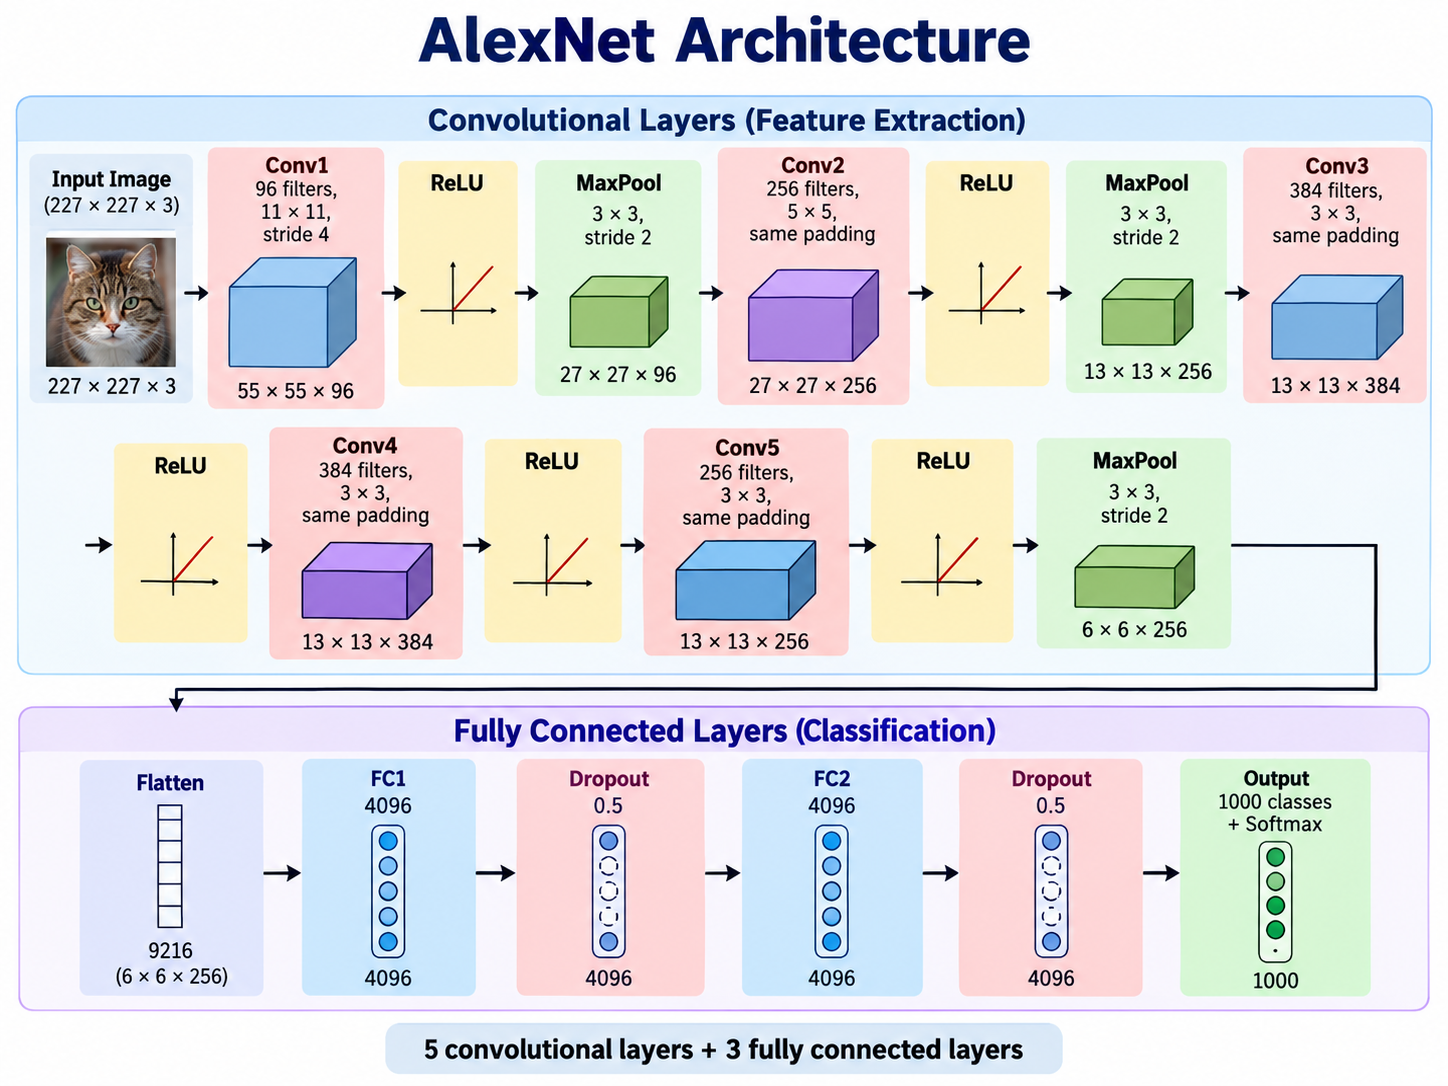
</div>

*AlexNet architecture visual: convolutional layers, pooling, flattening, and fully connected classifier.*


# 5. Conv1

### Input

$$
227\times227\times3
$$

### Conv1 settings

- Filters = **96**
- Kernel = $11\times11$
- Stride = $4$
- Padding = $0$

### Output-size calculation

$$
O=\frac{227-11+2(0)}{4}+1
$$

$$
O=\frac{216}{4}+1
$$

$$
O=54+1=55
$$

Therefore:

$$
\boxed{227\times227\times3
\rightarrow
55\times55\times96}
$$

### What does Conv1 learn?

Early filters usually respond to simple visual information such as:

- vertical edges;
- horizontal edges;
- diagonal edges;
- colour transitions;
- simple textures.

## Question 1

Suppose Conv1 used **128 filters** instead of 96, while keeping the same kernel, stride and padding.

What would be the output feature-map dimension?

### Solution

The spatial dimensions do **not** depend on the number of filters.

We already found:

$$
55\times55
$$

The output depth equals the number of filters:

$$
128
$$

Therefore:

$$
\boxed{55\times55\times128}
$$

# 6. First Max-Pooling Layer

### Input

$$
55\times55\times96
$$

### Pooling settings

- Pool size = $3\times3$
- Stride = $2$
- Padding = $0$

### Output-size calculation

$$
O=
\left\lfloor
\frac{55-3}{2}
\right\rfloor+1
$$

$$
O=\frac{52}{2}+1
$$

$$
O=26+1=27
$$

Therefore:

$$
\boxed{55\times55\times96
\rightarrow
27\times27\times96}
$$

### Important point

Pooling reduces:

- height;
- width.

It does **not** change the number of channels.

So the depth remains:

$$
96
$$

## Question 2

Why is the output depth after max pooling still **96**?

### Solution

Max pooling operates **independently on each feature map**.

It reduces the spatial size of every feature map but does not combine different channels.

Therefore:

$$
55\times55\times96
\rightarrow
27\times27\times96
$$

The number of channels remains unchanged.

# 7. Conv2

### Input

$$
27\times27\times96
$$

### Conv2 settings

- Filters = **256**
- Kernel = $5\times5$
- Stride = $1$
- Padding = **same**

For a $5\times5$ kernel with stride 1, same padding means:

$$
P=2
$$

### Output-size calculation

$$
O=
\frac{27-5+2(2)}{1}+1
$$

$$
O=27-5+4+1
$$

$$
O=27
$$

Therefore:

$$
\boxed{27\times27\times96
\rightarrow
27\times27\times256}
$$

### Feature interpretation

Conv2 can combine basic edges into:

- corners;
- textures;
- colour patterns;
- simple shapes.

# 8. Second Max-Pooling Layer

### Input

$$
27\times27\times256
$$

Pool:

- $3\times3$
- stride $2$
- no padding

### Output-size calculation

$$
O=
\left\lfloor
\frac{27-3}{2}
\right\rfloor+1
$$

$$
O=\frac{24}{2}+1
$$

$$
O=13
$$

Therefore:

$$
\boxed{27\times27\times256
\rightarrow
13\times13\times256}
$$

## Question 3

Suppose the input to a pooling layer is:

$$
27\times27\times256
$$

and we use a $3\times3$ pool with stride 2.

What is the output?

### Solution

$$
O=
\left\lfloor
\frac{27-3}{2}
\right\rfloor+1
=13
$$

Pooling does not change depth.

Therefore:

$$
\boxed{13\times13\times256}
$$

# 9. Conv3

### Input

$$
13\times13\times256
$$

### Conv3 settings

- Filters = **384**
- Kernel = $3\times3$
- Stride = $1$
- Padding = **same**

For $3\times3$:

$$
P=1
$$

### Output-size calculation

$$
O=
\frac{13-3+2(1)}{1}+1
$$

$$
O=13
$$

Therefore:

$$
\boxed{13\times13\times256
\rightarrow
13\times13\times384}
$$

At this depth, the network starts combining lower-level patterns into more complex features.

# 10. Conv4

### Input

$$
13\times13\times384
$$

### Conv4 settings

- Filters = **384**
- Kernel = $3\times3$
- Stride = $1$
- Padding = **same**

### Output-size calculation

$$
O=
\frac{13-3+2(1)}{1}+1
$$

$$
O=13
$$

Therefore:

$$
\boxed{13\times13\times384
\rightarrow
13\times13\times384}
$$

Conv4 can represent more complex combinations of previous features, such as object parts and higher-level textures.

## Question 4

Why does the spatial size remain $13\times13$ in Conv3 and Conv4?

### Solution

Both layers use:

- $3\times3$ kernels;
- stride $1$;
- padding $1$.

So:

$$
O=
\frac{13-3+2}{1}+1
=13
$$

This is the main purpose of **same padding**:

$$
\boxed{\text{preserve spatial dimensions when stride = 1}}
$$

# 11. Conv5

### Input

$$
13\times13\times384
$$

### Conv5 settings

- Filters = **256**
- Kernel = $3\times3$
- Stride = $1$
- Padding = **same**

### Output calculation

$$
O=
\frac{13-3+2(1)}{1}+1
$$

$$
O=13
$$

Therefore:

$$
\boxed{13\times13\times384
\rightarrow
13\times13\times256}
$$

# 12. Third Max-Pooling Layer

### Input

$$
13\times13\times256
$$

Settings:

- Pool = $3\times3$
- Stride = $2$
- Padding = $0$

### Output-size calculation

$$
O=
\left\lfloor
\frac{13-3}{2}
\right\rfloor+1
$$

$$
O=\frac{10}{2}+1
$$

$$
O=6
$$

Therefore:

$$
\boxed{13\times13\times256
\rightarrow
6\times6\times256}
$$

# 13. Flatten and Fully Connected Layers

After the final pooling layer:

$$
6\times6\times256
$$

Flattening converts the 3-D tensor into a 1-D vector:

$$
6\times6\times256=9216
$$

Therefore:

$$
\boxed{6\times6\times256\rightarrow9216}
$$

Then:

$$
9216
\rightarrow
4096
\rightarrow
4096
\rightarrow
1000
$$

The final 1000 neurons correspond to the **1000 ImageNet classes**.

A **Softmax** converts the final scores into class probabilities.

# 14. Why ReLU?

AlexNet uses:

$$
\boxed{ReLU(x)=\max(0,x)}
$$

Examples:

$$
-5\rightarrow0
$$

$$
3\rightarrow3
$$

### Why was ReLU useful?

- computationally simple;
- introduces non-linearity;
- does not saturate on the positive side like sigmoid;
- helped deep CNNs train much faster.

# 15. Why Dropout?

AlexNet uses dropout in the fully connected part of the network.

Typical dropout rate:

$$
\boxed{0.5}
$$

During training, some neurons are randomly disabled.

### Purpose

- reduces overfitting;
- prevents neurons from depending too strongly on one another;
- encourages more robust feature learning.

Dropout is normally used during **training**, not during inference.

# 16. Data Augmentation

AlexNet also used data augmentation to increase the effective variety of training examples.

Examples:

- random image crops;
- horizontal flipping;
- colour/intensity changes.

### Why?

The network sees slightly different versions of the same object.

This helps improve **generalization** and reduces overfitting.

# 17. How features become more complex

A useful intuition is:

```text
Input image
    ↓
Conv1
edges, lines, colour transitions
    ↓
Conv2
corners and textures
    ↓
Conv3
patterns and combinations of textures
    ↓
Conv4
higher-level structures / object parts
    ↓
Conv5
more abstract object-related representations
    ↓
Fully connected layers
combine the learned evidence
    ↓
Softmax
predict the class
```

For example, for a dog image, the hierarchy might roughly behave like:

```text
edges
  ↓
fur-like textures
  ↓
curved shapes
  ↓
ear / eye / body-part-like patterns
  ↓
dog-related representation
```

This is only an intuition — individual CNN filters do not always correspond cleanly to one human-readable concept.

### Visual: How AlexNet Learns Features

<div style="text-align:center; margin: 12px 0 18px 0;">
  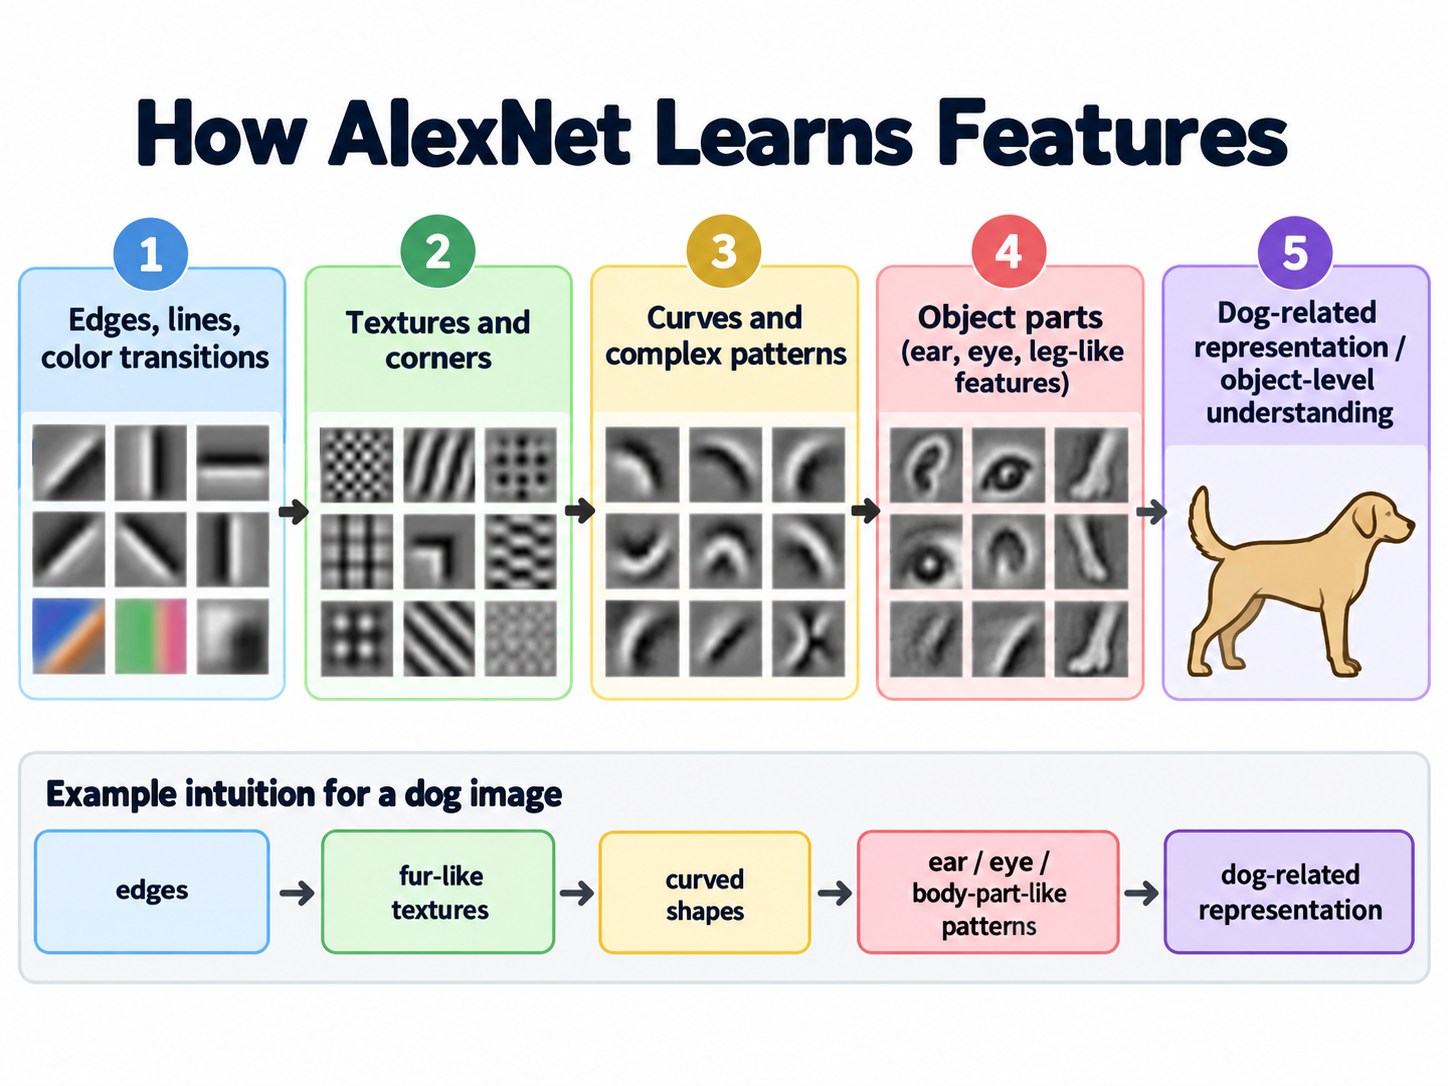
</div>

*Feature hierarchy from edges and textures to object parts and object-level understanding.*


# 18. AlexNet Architecture Summary

| Stage | Operation | Output size |
|---|---|---|
| Input | RGB image | $227\times227\times3$ |
| Conv1 | 96 filters, $11\times11$, S=4 | $55\times55\times96$ |
| Pool1 | $3\times3$, S=2 | $27\times27\times96$ |
| Conv2 | 256 filters, $5\times5$, same | $27\times27\times256$ |
| Pool2 | $3\times3$, S=2 | $13\times13\times256$ |
| Conv3 | 384 filters, $3\times3$, same | $13\times13\times384$ |
| Conv4 | 384 filters, $3\times3$, same | $13\times13\times384$ |
| Conv5 | 256 filters, $3\times3$, same | $13\times13\times256$ |
| Pool3 | $3\times3$, S=2 | $6\times6\times256$ |
| Flatten | — | $9216$ |
| FC1 | Dense | 4096 |
| FC2 | Dense | 4096 |
| Output | Dense + Softmax | 1000 |

# 19. LeNet-5 vs AlexNet vs VGG-16

| Feature | LeNet-5 | AlexNet | VGG-16 |
|---|---|---|---|
| Main task | Handwritten digits | Large-scale image classification | Large-scale image classification |
| Input type | Grayscale | RGB | RGB |
| Conv layers | 2 | 5 | 13 |
| Fully connected layers | 3 | 3 | 3 |
| Main conv kernels | $5\times5$ | $11\times11,\ 5\times5,\ 3\times3$ | Mostly $3\times3$ |
| Activation | Historically tanh/sigmoid-like | ReLU | ReLU |
| Pooling | Average/subsampling | Max pooling | Max pooling |
| Dropout | No | Yes | Yes |
| Main idea | Early practical CNN | Scale CNNs to real-world images | Go deeper using repeated small filters |

### Evolution

$$
\boxed{
\text{LeNet: CNN works}
\rightarrow
\text{AlexNet: CNN scales}
\rightarrow
\text{VGG: CNN goes deeper}
}
$$

### Important AlexNet vs VGG idea

AlexNet uses a mixture of:

$$
11\times11,\;5\times5,\;3\times3
$$

VGG-16 mainly uses repeated:

$$
\boxed{3\times3}
$$

convolutions.

Stacking small filters allows VGG to build a deeper architecture with repeated nonlinearities.

### Visual Comparison: LeNet-5 vs AlexNet vs VGG-16

<div style="text-align:center; margin: 12px 0 18px 0;">
  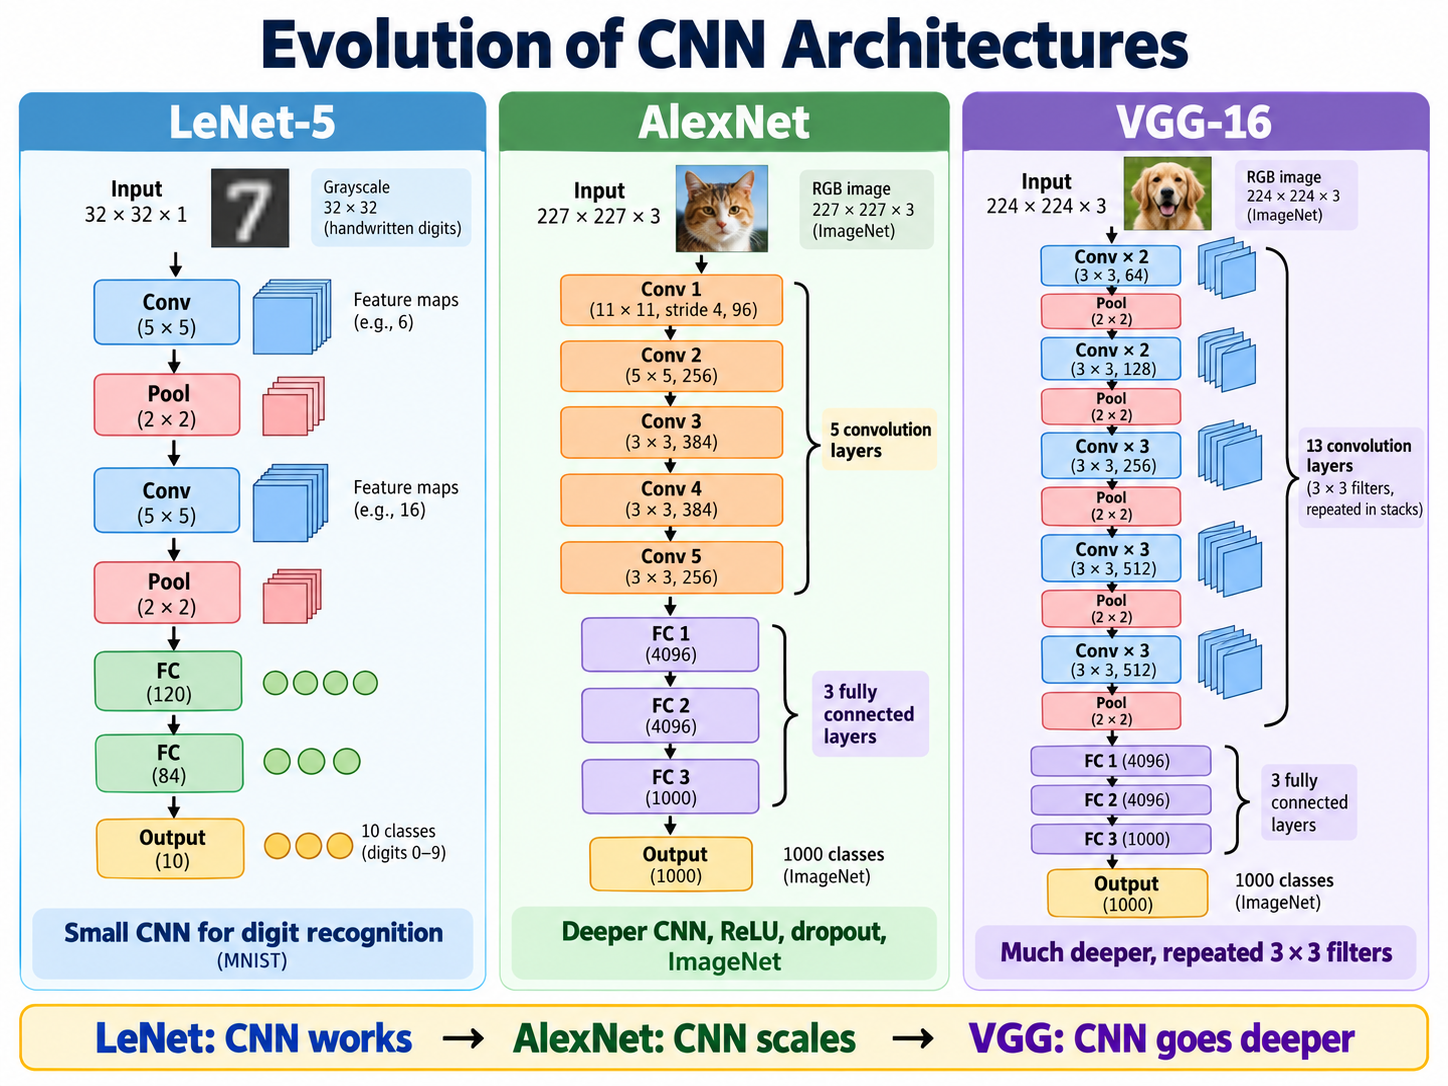
</div>

*A side-by-side visual showing the evolution from LeNet-5 to AlexNet to VGG-16.*


# 20. Quick Revision Questions

### Q1. How many convolutional layers are present in AlexNet?

**Answer:** 5

---

### Q2. How many fully connected layers are present?

**Answer:** 3

---

### Q3. What is the filter sequence?

$$
\boxed{96\rightarrow256\rightarrow384\rightarrow384\rightarrow256}
$$

---

### Q4. Which activation made AlexNet especially important?

**Answer:** ReLU

---

### Q5. Why is dropout used?

**Answer:** To reduce overfitting.

---

### Q6. Why does a convolution with same padding and stride 1 preserve spatial size?

Because padding compensates for the reduction caused by the kernel.

For a $3\times3$ filter:

$$
P=1
$$

gives:

$$
O=N
$$

---

### Q7. What is the final convolutional output before flattening?

$$
\boxed{6\times6\times256}
$$

# 21. Implementing AlexNet with Keras

Now we will implement the architecture.

### Teaching implementation

We will use:

- input size: `227 × 227 × 3`
- 5 convolutional layers;
- 3 max-pooling layers;
- ReLU activation;
- 2 fully connected hidden layers;
- dropout;
- 1000-class softmax output.

> To keep the implementation clear, we will use the single-stream architecture commonly taught today and omit the original two-GPU split.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## 22. Build the AlexNet model

Notice how the Keras layer sequence follows exactly the architecture derived above.

In [ ]:
alexnet = keras.Sequential([
    layers.Input(shape=(227, 227, 3), name="Input"),

    # Conv Block 1
    layers.Conv2D(
        filters=96,
        kernel_size=(11, 11),
        strides=(4, 4),
        padding="valid",
        activation="relu",
        name="Conv1"
    ),
    layers.MaxPooling2D(
        pool_size=(3, 3),
        strides=(2, 2),
        name="Pool1"
    ),

    # Conv Block 2
    layers.Conv2D(
        filters=256,
        kernel_size=(5, 5),
        strides=(1, 1),
        padding="same",
        activation="relu",
        name="Conv2"
    ),
    layers.MaxPooling2D(
        pool_size=(3, 3),
        strides=(2, 2),
        name="Pool2"
    ),

    # Conv Block 3
    layers.Conv2D(
        filters=384,
        kernel_size=(3, 3),
        strides=(1, 1),
        padding="same",
        activation="relu",
        name="Conv3"
    ),

    # Conv Block 4
    layers.Conv2D(
        filters=384,
        kernel_size=(3, 3),
        strides=(1, 1),
        padding="same",
        activation="relu",
        name="Conv4"
    ),

    # Conv Block 5
    layers.Conv2D(
        filters=256,
        kernel_size=(3, 3),
        strides=(1, 1),
        padding="same",
        activation="relu",
        name="Conv5"
    ),
    layers.MaxPooling2D(
        pool_size=(3, 3),
        strides=(2, 2),
        name="Pool3"
    ),

    # Fully Connected Classifier
    layers.Flatten(name="Flatten"),

    layers.Dense(4096, activation="relu", name="FC1"),
    layers.Dropout(0.5, name="Dropout1"),

    layers.Dense(4096, activation="relu", name="FC2"),
    layers.Dropout(0.5, name="Dropout2"),

    layers.Dense(1000, activation="softmax", name="Output")
], name="AlexNet")

alexnet.summary()

Model: "AlexNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv1 (Conv2D)                  │ (None, 55, 55, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pool1 (MaxPooling2D)            │ (None, 27, 27, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2 (Conv2D)                  │ (None, 27, 27, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pool2 (MaxPooling2D)            │ (None, 13, 13, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv3 (Conv2D)                  │ (None, 13, 13, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv4 (Conv2D)                  │ (None, 13, 13, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv5 (Conv2D)                  │ (None, 13, 13, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pool3 (MaxPooling2D)            │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ FC1 (Dense)                     │ (None, 4096)           │    37,752,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout1 (Dropout)              │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ FC2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout2 (Dropout)              │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,378,344 (237.95 MB)

 Trainable params: 62,378,344 (237.95 MB)

 Non-trainable params: 0 (0.00 B)

# 23. Check the output dimensions automatically

The next cell prints the output shape after every layer.

Compare these values with the manual calculations:

$$
227
\rightarrow55
\rightarrow27
\rightarrow27
\rightarrow13
\rightarrow13
\rightarrow13
\rightarrow13
\rightarrow6
$$

In [ ]:
for layer in alexnet.layers:
    try:
        print(f"{layer.name:12s} -> {layer.output.shape}")
    except:
        pass

Conv1        -> (None, 55, 55, 96)
Pool1        -> (None, 27, 27, 96)
Conv2        -> (None, 27, 27, 256)
Pool2        -> (None, 13, 13, 256)
Conv3        -> (None, 13, 13, 384)
Conv4        -> (None, 13, 13, 384)
Conv5        -> (None, 13, 13, 256)
Pool3        -> (None, 6, 6, 256)
Flatten      -> (None, 9216)
FC1          -> (None, 4096)
Dropout1     -> (None, 4096)
FC2          -> (None, 4096)
Dropout2     -> (None, 4096)
Output       -> (None, 1000)


# 24. Compile the model

For a 1000-class classification task, categorical cross-entropy or sparse categorical cross-entropy can be used.

Here we use:

- **Adam optimizer**
- **Sparse Categorical Crossentropy**
- **Accuracy**

This is a convenient modern training setup for demonstration.

> The optimizer used here is for teaching convenience and is not meant to reproduce every detail of the original 2012 training procedure.

In [ ]:
alexnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


# 28. Final Takeaway

Remember AlexNet using the following sequence:

$$
\boxed{
227\times227\times3
}
$$

$$
\downarrow
$$

$$
\boxed{
96\rightarrow256\rightarrow384\rightarrow384\rightarrow256
}
$$

$$
\downarrow
$$

$$
\boxed{
6\times6\times256
}
$$

$$
\downarrow
$$

$$
\boxed{
4096\rightarrow4096\rightarrow1000
}
$$

### Core ideas to remember

- AlexNet has **5 convolutional + 3 fully connected layers**.
- The first convolution uses a large $11\times11$ filter with stride 4.
- Later convolutions use smaller kernels.
- ReLU allows efficient non-linear feature learning.
- Max pooling reduces spatial size.
- Dropout reduces overfitting.
- Deeper layers learn increasingly abstract visual representations.
- AlexNet demonstrated that deep CNNs can scale successfully to large real-world image classification problems.
- VGG-16 later made the design deeper and more systematic using repeated $3\times3$ convolutions.